### Codi copiat de la web

In [15]:
import torch
import torchoptics
from torch.nn import Parameter
from torchoptics import Field, System
from torchoptics.elements import PhaseModulator
from torchoptics.profiles import gaussian, laguerre_gaussian, circle
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
torchoptics.set_default_spacing(10e-6)
torchoptics.set_default_wavelength(700e-9)

shape = 250
waist_radius = 300e-6

input_field = Field(gaussian(shape, waist_radius=waist_radius), z=0).to(device)

petal_profile = laguerre_gaussian(shape, p=0, l=4, waist_radius=waist_radius)
petal_profile += laguerre_gaussian(shape, p=0, l=-4, waist_radius=waist_radius)
target_field = Field(circle(shape, radius = waist_radius), z=0.8).normalize().to(device)

system = System(
    PhaseModulator(Parameter(torch.zeros(shape, shape)), z=0.2),
    PhaseModulator(Parameter(torch.zeros(shape, shape)), z=0.4),
    PhaseModulator(Parameter(torch.zeros(shape, shape)), z=0.6),
).to(device)


losses = []
optimizer = torch.optim.Adam(system.parameters(), lr=0.05)
for iteration in range(100):
    optimizer.zero_grad()
    output_field = system.measure_at_z(input_field, 0.8)
    loss = 1 - output_field.inner(target_field).abs().square()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

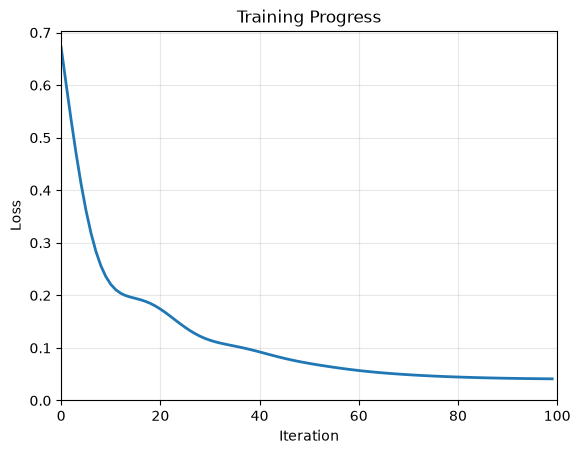

In [17]:
plt.plot(losses, linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Progress")
plt.xlim(0, len(losses))
plt.ylim(0)
plt.grid(True, alpha=0.3)
plt.show()

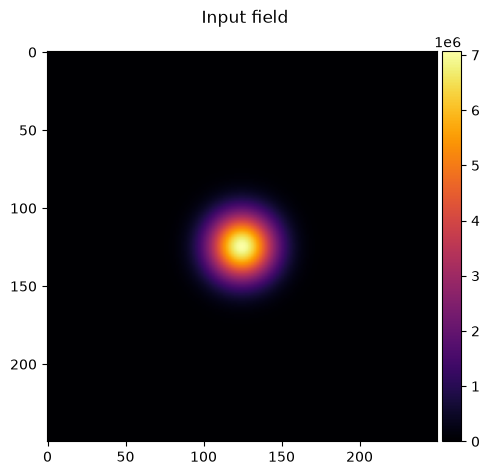

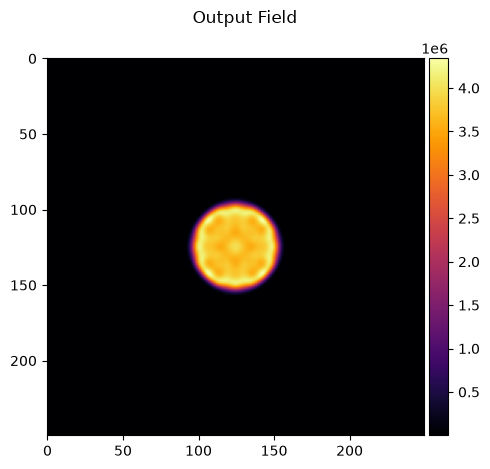

In [19]:
visualize_tensor(input_field.intensity(), title="Input field")

output_field = system.measure_at_z(input_field, 0.8)
visualize_tensor(output_field.intensity(), title="Output Field")

PhaseModulator(shape=(250, 250), z=2.00e-01, spacing=(1.00e-05, 1.00e-05), offset=(0.00e+00, 0.00e+00))


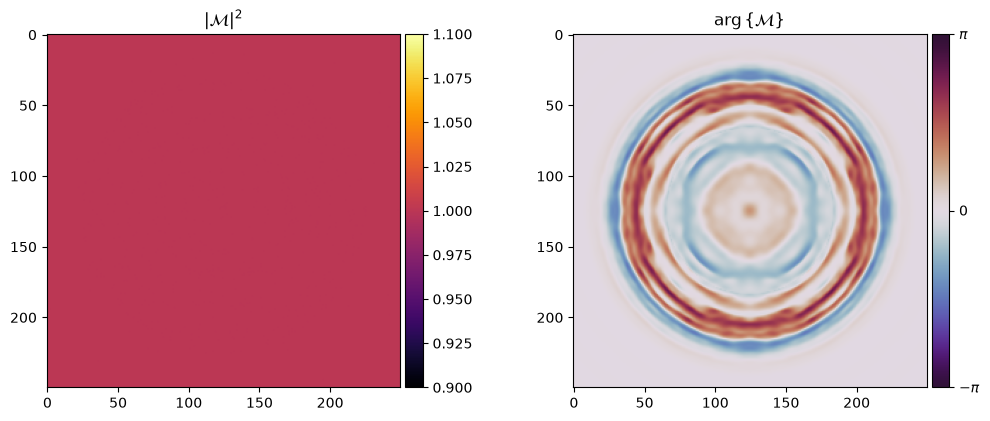

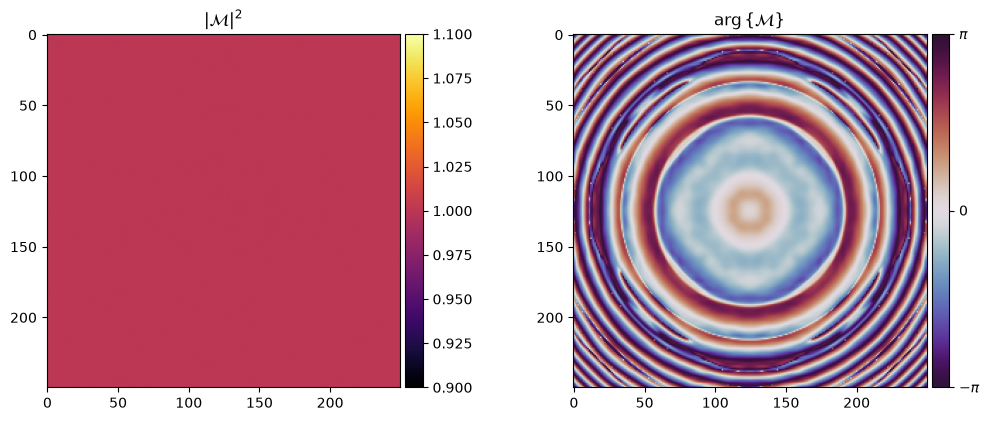

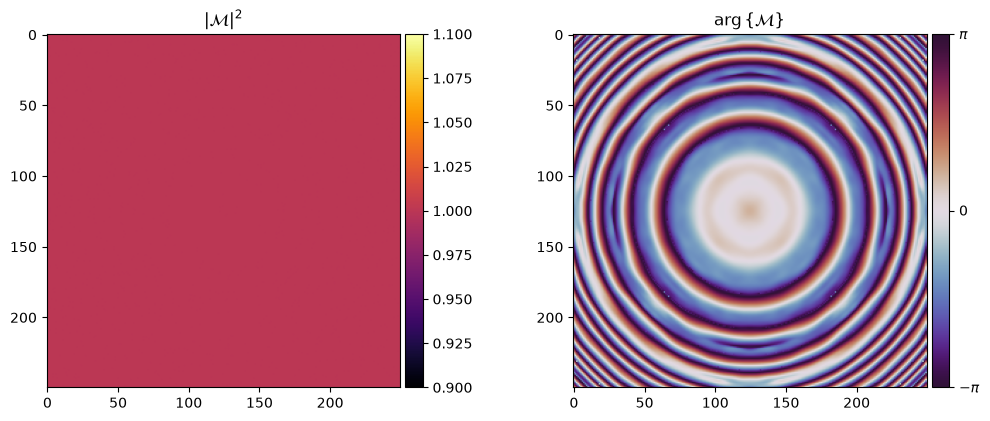

In [14]:
print(system[0])

import matplotlib.pyplot as plt
from torchoptics import Field, System, visualize_tensor

system[0].visualize()
system[1].visualize()
system[2].visualize()
#plt.imshow(system[0])